In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import os

from sklearn.model_selection import StratifiedKFold
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense


# --------------------------------
# 1. Download Kaggle dataset
# --------------------------------
path = kagglehub.dataset_download("shayanfazeli/heartbeat")

print("Path to dataset files:", path)


# --------------------------------
# 2. Load ECG training data
# --------------------------------
file_path = os.path.join(path, "mitbih_train.csv")

data = pd.read_csv(file_path, header=None)

X = data.iloc[:, :-1].values    # ECG signals in this last column is not included as i shows the labels
y = data.iloc[:, -1].values     # Labels

# Convert shape for 1D CNN
X = X.reshape(X.shape[0], X.shape[1], 1)

print("X shape:", X.shape)
print("y shape:", y.shape)


# --------------------------------
# 3. 5-Fold Cross Validation
# --------------------------------
kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []


for fold, (train_idx, val_idx) in enumerate(kf.split(X, y), 1):

    print("\nFold:", fold)

    X_train = X[train_idx]
    X_val = X[val_idx]

    y_train = y[train_idx]
    y_val = y[val_idx]


    # --------------------------------
    # 4. Simple 1D CNN
    # --------------------------------
    model = Sequential([
        Conv1D(32, 3, activation="relu",
               input_shape=(X.shape[1], 1)),

        MaxPooling1D(2),

        Flatten(),

        Dense(32, activation="relu"),

        Dense(5, activation="softmax")
    ])


    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )


    # --------------------------------
    # 5. Train
    # --------------------------------
    model.fit(
        X_train,
        y_train,
        epochs=3,
        batch_size=128,
        verbose=1
    )


    # --------------------------------
    # 6. Validate
    # --------------------------------
    loss, accuracy = model.evaluate(
        X_val,
        y_val,
        verbose=0
    )

    print("Validation Accuracy:", accuracy)

    scores.append(accuracy)


# --------------------------------
# 7. Final Result
# --------------------------------
print("\nAccuracy of each fold:")
print(scores)

print("\nAverage Accuracy:")
print(np.mean(scores))

100%|██████████| 98.8M/98.8M [00:00<00:00, 128MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/shayanfazeli/heartbeat/versions/1
X shape: (87554, 187, 1)
y shape: (87554,)

Fold: 1


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/3
548/548 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.8929 - loss: 0.3758
Epoch 2/3
548/548 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.9414 - loss: 0.2166
Epoch 3/3
548/548 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.9525 - loss: 0.1768
Validation Accuracy: 0.9588258862495422

Fold: 2
Epoch 1/3
548/548 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.8824 - loss: 0.4140
Epoch 2/3
548/548 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.9350 - loss: 0.2333
Epoch 3/3
548/548 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9484 - loss: 0.1905
Validation Accuracy: 0.9541431069374084

Fold: 3
Epoch 1/3
548/548 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.8852 - loss: 0.4012
Epoch 2/3
548/548 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9382 - loss: 0.2213
Epoch 3/3
548/548 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.9518 - loss: 0.1823
Validation Accuracy: 0.9581406116485596

Fold: 4
Epoch 1/3
548/548 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.8917 

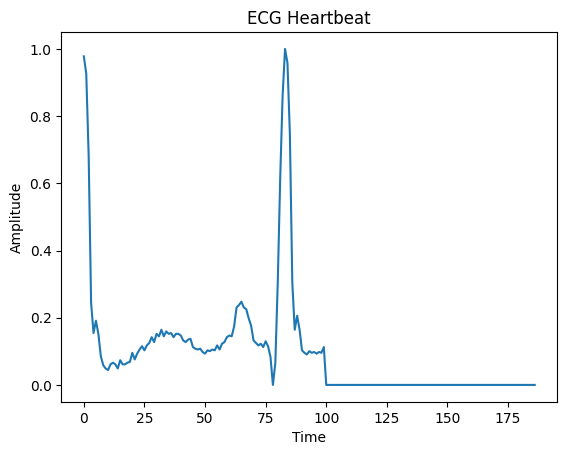

In [ ]:
import matplotlib.pyplot as plt

# Plot one ECG signal
plt.plot(X[0].flatten())

plt.title("ECG Heartbeat")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.show()

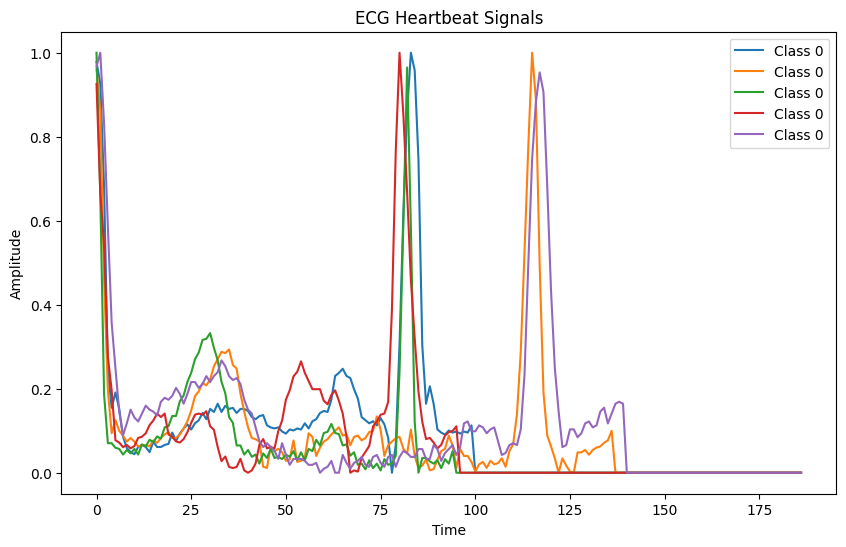

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for i in range(5):
    plt.plot(X[i].flatten(), label=f"Class {int(y[i])}")

plt.title("ECG Heartbeat Signals")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.legend()
plt.show()

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense


# --------------------------------
# 1. Download dataset
# --------------------------------
path = kagglehub.dataset_download("shayanfazeli/heartbeat")

print("Dataset path:", path)


# --------------------------------
# 2. Load training and test data
# --------------------------------
train_data = pd.read_csv(
    os.path.join(path, "mitbih_train.csv"),
    header=None
)

test_data = pd.read_csv(
    os.path.join(path, "mitbih_test.csv"),
    header=None
)


# --------------------------------
# 3. Separate X and y
# --------------------------------
X_train = train_data.iloc[:, :-1].values
y_train = train_data.iloc[:, -1].values

X_test = test_data.iloc[:, :-1].values
y_test = test_data.iloc[:, -1].values


# CNN input shape
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)


# --------------------------------
# 4. K-Fold Cross Validation
# --------------------------------
kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train, y_train), 1):

    print("Fold:", fold)

    model = Sequential([
        Conv1D(32, 3, activation="relu",
               input_shape=(X_train.shape[1], 1)),
        MaxPooling1D(2),
        Flatten(),
        Dense(32, activation="relu"),
        Dense(5, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        X_train[train_idx],
        y_train[train_idx],
        epochs=3,
        batch_size=128,
        verbose=0
    )

    loss, accuracy = model.evaluate(
        X_train[val_idx],
        y_train[val_idx],
        verbose=0
    )

    print("Validation Accuracy:", accuracy)

    scores.append(accuracy)


# --------------------------------
# 5. Average K-Fold accuracy
# --------------------------------
print("\nK-Fold Accuracies:", scores)
print("Average K-Fold Accuracy:", np.mean(scores))


# --------------------------------
# 6. Train final model on ALL training data
# --------------------------------
model = Sequential([
    Conv1D(32, 3, activation="relu",
           input_shape=(X_train.shape[1], 1)),
    MaxPooling1D(2),
    Flatten(),
    Dense(32, activation="relu"),
    Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=128,
    verbose=1
)


# --------------------------------
# 7. Test Accuracy
# --------------------------------
loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nTEST ACCURACY:", test_accuracy)

Using Colab cache for faster access to the 'heartbeat' dataset.
Dataset path: /kaggle/input/heartbeat
Fold: 1


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Validation Accuracy: 0.9535149335861206
Fold: 2
Validation Accuracy: 0.9523156881332397
Fold: 3
Validation Accuracy: 0.9542573094367981
Fold: 4
Validation Accuracy: 0.9485466480255127
Fold: 5
Validation Accuracy: 0.9464306235313416

K-Fold Accuracies: [0.9535149335861206, 0.9523156881332397, 0.9542573094367981, 0.9485466480255127, 0.9464306235313416]
Average K-Fold Accuracy: 0.9510130405426025
Epoch 1/3
685/685 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.8901 - loss: 0.3807
Epoch 2/3
685/685 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.9365 - loss: 0.2274
Epoch 3/3
685/685 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.9519 - loss: 0.1795

TEST ACCURACY: 0.9532706141471863


using random forest

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import os

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier


# --------------------------------
# 1. Download dataset
# --------------------------------
path = kagglehub.dataset_download("shayanfazeli/heartbeat")

# --------------------------------
# 2. Load data
# --------------------------------
train_data = pd.read_csv(
    os.path.join(path, "mitbih_train.csv"),
    header=None
)

test_data = pd.read_csv(
    os.path.join(path, "mitbih_test.csv"),
    header=None
)


# --------------------------------
# 3. Separate X and y
# --------------------------------
X_train = train_data.iloc[:, :-1].values
y_train = train_data.iloc[:, -1].values

X_test = test_data.iloc[:, :-1].values
y_test = test_data.iloc[:, -1].values


# --------------------------------
# 4. 5-Fold Cross Validation
# --------------------------------
kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train, y_train), 1):

    print("Fold:", fold)

    model = RandomForestClassifier(
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train[train_idx], y_train[train_idx])

    accuracy = model.score(
        X_train[val_idx],
        y_train[val_idx]
    )

    print("Validation Accuracy:", accuracy)

    scores.append(accuracy)


# --------------------------------
# 5. Average K-Fold Accuracy
# --------------------------------
print("\nK-Fold Accuracies:", scores)
print("Average K-Fold Accuracy:", np.mean(scores))


# --------------------------------
# 6. Train final model
# --------------------------------
model.fit(X_train, y_train)


# --------------------------------
# 7. Test Accuracy
# --------------------------------
test_accuracy = model.score(X_test, y_test)

print("\nTest Accuracy:", test_accuracy)

Using Colab cache for faster access to the 'heartbeat' dataset.
Fold: 1
Validation Accuracy: 0.9748729370110216
Fold: 2
Validation Accuracy: 0.975101364856376
Fold: 3
Validation Accuracy: 0.9760150762377934
Fold: 4
Validation Accuracy: 0.9757295414311005
Fold: 5
Validation Accuracy: 0.9727013135351228

K-Fold Accuracies: [0.9748729370110216, 0.975101364856376, 0.9760150762377934, 0.9757295414311005, 0.9727013135351228]
Average K-Fold Accuracy: 0.9748840466142829

Test Accuracy: 0.9741458066873744


using_svm

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import os

from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler


# --------------------------------
# 1. Download dataset
# --------------------------------
path = kagglehub.dataset_download("shayanfazeli/heartbeat")

# --------------------------------
# 2. Load data
# --------------------------------
train_data = pd.read_csv(
    os.path.join(path, "mitbih_train.csv"),
    header=None
)

test_data = pd.read_csv(
    os.path.join(path, "mitbih_test.csv"),
    header=None
)


# --------------------------------
# 3. Separate X and y
# --------------------------------
X_train = train_data.iloc[:, :-1].values
y_train = train_data.iloc[:, -1].values

X_test = test_data.iloc[:, :-1].values
y_test = test_data.iloc[:, -1].values


# --------------------------------
# 4. Scale the data
# --------------------------------
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


# --------------------------------
# 5. 5-Fold Cross Validation
# --------------------------------
kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train, y_train), 1):

    print("Fold:", fold)

    model = LinearSVC(
        C=1,
        max_iter=2000,
        random_state=42
    )

    model.fit(
        X_train[train_idx],
        y_train[train_idx]
    )

    accuracy = model.score(
        X_train[val_idx],
        y_train[val_idx]
    )

    print("Validation Accuracy:", accuracy)

    scores.append(accuracy)


# --------------------------------
# 6. Average K-Fold Accuracy
# --------------------------------
print("\nK-Fold Accuracies:", scores)
print("Average K-Fold Accuracy:", np.mean(scores))


# --------------------------------
# 7. Train final model
# --------------------------------
model.fit(X_train, y_train)


# --------------------------------
# 8. Test Accuracy
# --------------------------------
test_accuracy = model.score(X_test, y_test)

print("\nTest Accuracy:", test_accuracy)

Using Colab cache for faster access to the 'heartbeat' dataset.
Fold: 1
Validation Accuracy: 0.9049169093712524
Fold: 2
Validation Accuracy: 0.9057735137913312
Fold: 3
Validation Accuracy: 0.9045742676032208
Fold: 4
Validation Accuracy: 0.902061561304323
Fold: 5
Validation Accuracy: 0.9032552826956025

K-Fold Accuracies: [0.9049169093712524, 0.9057735137913312, 0.9045742676032208, 0.902061561304323, 0.9032552826956025]
Average K-Fold Accuracy: 0.904116306953146

Test Accuracy: 0.9046683720080395
